In [1]:
!git clone https://github.com/DeepMIMO/DeepMIMO.git
%cd DeepMIMO
!pip install -qq -e .[dev]

Cloning into 'DeepMIMO'...
remote: Enumerating objects: 10037, done.
remote: Counting objects: 100% (1625/1625), done.
remote: Compressing objects: 100% (522/522), done.
remote: Total 10037 (delta 1321), reused 1114 (delta 1103), pack-reused 8412 (from 2)
Receiving objects: 100% (10037/10037), 42.02 MiB | 43.47 MiB/s, done.
Resolving deltas: 100% (6889/6889), done.
/content/DeepMIMO
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.4/107.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 57.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 139.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.9/268

In [2]:
#asu_campus_3p5...outdoor
#i2_28b...indoor...used in HF
#
import deepmimo as dm

# Download a dataset
dm.download('city_11_santaclara_28')

# Load a dataset
dataset = dm.load('city_11_santaclara_28')

# Generate channels
#channels = dataset.compute_channels()  # [n_ue, n_rx, n_tx, n_sub]

Downloading: 100%|██████████| 52.8M/52.8M [00:00<00:00, 95.3MB/s]


✓ Downloaded to /content/DeepMIMO/deepmimo_scenarios/city_11_santaclara_28_downloaded.zip


Extracting: 100%|██████████| 135/135 [00:00<00:00, 180.68file/s]


✓ Unzipped and moved to /content/DeepMIMO/deepmimo_scenarios
✓ Scenario 'city_11_santaclara_28' ready to use!
Loading TXRX PAIR: TXset 1 (tx_idx 0) & RXset 0 (rx_idxs 33345)
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 33345)
Loading TXRX PAIR: TXset 3 (tx_idx 0) & RXset 0 (rx_idxs 33345)


In [3]:
import deepmimo as dm
import numpy as np

ch_params = dm.ChannelParameters()

# BS antenna array..32 original
ch_params.bs_antenna.shape = [32,1]

# OFDM configuration...subcarriers=512 original
ch_params.ofdm.bandwidth = 50e6
ch_params.ofdm.subcarriers = 512
ch_params.ofdm.selected_subcarriers = np.arange(512)

# number of strongest paths used
ch_params.num_paths = 25

channels = dataset.compute_channels(ch_params)

#print("Channel shape:", channels.shape)

Generating channels: 100%|██████████| 33345/33345 [00:29<00:00, 1133.55it/s]


In [4]:
print(dataset['power'][0])

[[ -99.5914 -101.727  -110.405  ... -140.219  -140.596  -141.227 ]
 [ -99.4873 -124.584  -127.04   ... -141.089  -141.373  -142.247 ]
 [ -99.3821 -124.457  -126.934  ... -140.949  -141.189  -142.163 ]
 ...
 [-108.463  -110.097  -142.483  ... -158.346        nan       nan]
 [-108.498  -110.126  -143.576  ... -158.32         nan       nan]
 [-108.533  -110.155  -144.584  ... -158.346        nan       nan]]


In [5]:
print(type(channels))
print(len(channels))
print(type(channels[0]))

<class 'list'>
3
<class 'numpy.ndarray'>


In [6]:
print(channels[0].shape)

(33345, 1, 32, 512)


In [7]:
import numpy as np

#print(channels.shape)

# Example: CSI for user 0
H = channels[0]    # shape [n_rx, n_tx, n_sub]

print(H.shape)

(33345, 1, 32, 512)


In [8]:
dataset

In [9]:
print(dataset.keys())

[dict_keys(['aoa_az', 'aoa_el', 'aod_az', 'aod_el', 'power', 'phase', 'delay', 'rx_pos', 'tx_pos', 'inter', 'inter_pos', 'txrx', 'load_params', 'name', 'rt_params', 'scene', 'materials', 'n_ue', 'ch_params', '_aod_el_rot', '_aod_az_rot', '_aoa_el_rot', '_aoa_az_rot', '_tx_vel', '_rx_vel', 'power_linear', '_power_linear_ant_gain', 'channel']), dict_keys(['aoa_az', 'aoa_el', 'aod_az', 'aod_el', 'power', 'phase', 'delay', 'rx_pos', 'tx_pos', 'inter', 'inter_pos', 'txrx', 'load_params', 'name', 'rt_params', 'scene', 'materials', 'n_ue', 'ch_params', '_aod_el_rot', '_aod_az_rot', '_aoa_el_rot', '_aoa_az_rot', '_tx_vel', '_rx_vel', 'power_linear', '_power_linear_ant_gain', 'channel']), dict_keys(['aoa_az', 'aoa_el', 'aod_az', 'aod_el', 'power', 'phase', 'delay', 'rx_pos', 'tx_pos', 'inter', 'inter_pos', 'txrx', 'load_params', 'name', 'rt_params', 'scene', 'materials', 'n_ue', 'ch_params', '_aod_el_rot', '_aod_az_rot', '_aoa_el_rot', '_aoa_az_rot', '_tx_vel', '_rx_vel', 'power_linear', '_powe

In [10]:
import numpy as np

channels = dataset['channel']

#print(channels.shape)

In [11]:
H = channels[1][0]   # remove RX dimension
print(H.shape)

(1, 32, 512)


In [12]:
H = channels[1][0].squeeze()
print(H.shape)

(32, 512)


In [13]:
import numpy as np

#print("Power shape:", dataset['power'].shape)
print("First UE powers:", dataset['power'][0])

First UE powers: [[ -99.5914 -101.727  -110.405  ... -140.219  -140.596  -141.227 ]
 [ -99.4873 -124.584  -127.04   ... -141.089  -141.373  -142.247 ]
 [ -99.3821 -124.457  -126.934  ... -140.949  -141.189  -142.163 ]
 ...
 [-108.463  -110.097  -142.483  ... -158.346        nan       nan]
 [-108.498  -110.126  -143.576  ... -158.32         nan       nan]
 [-108.533  -110.155  -144.584  ... -158.346        nan       nan]]


In [14]:
# def normalize(x):
#     return (x - x.min())/(x.max()-x.min()+1e-12)


In [15]:
def add_noise(H, snr_db):
    snr = 10**(snr_db / 10)

    signal_power = np.mean(np.abs(H)**2)
    noise_power = signal_power / snr

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(*H.shape) + 1j*np.random.randn(*H.shape)
    )

    return H + noise

In [16]:
fading_depth_list = []
freq_selectivity_list = []
antenna_corr_list = []
beam_list = []
num_samples=5000
#snr=0
for i in range(num_samples):
    H = channels[0][i].squeeze()
    #H = add_noise(H, snr_db=snr)   # change SNR here
    H_mag = np.abs(H)

    fading_depth = np.max(H_mag) - np.min(H_mag)
    freq_selectivity = np.var(H_mag, axis=0).mean()
    antenna_corr = np.mean(np.corrcoef(H_mag))
    beam_spec = np.abs(np.fft.fft(H, axis=0)).mean(axis=1)
    beam = np.argmax(beam_spec)

    beam_list.append(beam)

    fading_depth_list.append(fading_depth)
    freq_selectivity_list.append(freq_selectivity)
    antenna_corr_list.append(antenna_corr)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


In [17]:
fade_t1, fade_t2 = np.percentile(fading_depth_list, [33, 66])
fs_t1, fs_t2 = np.percentile(freq_selectivity_list, [33, 66])
corr_t1, corr_t2 = np.percentile(antenna_corr_list, [33, 66])
beam_t1, beam_t2, beam_t3 = np.percentile(beam_list, [25, 50, 75])

In [18]:
!rm -rf /content/DeepMIMO/hf_csi_dataset

In [19]:
import numpy as np
import os
from skimage.transform import resize
from PIL import Image
import pandas as pd


# ----------------------------
# Normalization helper
# ----------------------------
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-12)


os.makedirs("hf_csi_dataset/images", exist_ok=True)

data_rows = []

num_samples = 5000


for i in range(num_samples):

    # ----------------------------
    # Load CSI matrix
    # ----------------------------
    #H = channels[i].squeeze()
    H = channels[0][i].squeeze()
    # for noise only
    #H = add_noise(H, snr_db=snr)   # change SNR here
    #
    H_mag = np.abs(H)
    H_phase = np.angle(H)

    # Angular spectrum
    H_ang = np.abs(np.fft.fft(H, axis=0))


    # ----------------------------
    # Create RGB CSI image
    # ----------------------------
    mag_img = resize(normalize(H_mag), (224,224))
    phase_img = resize(normalize(H_phase), (224,224))
    ang_img = resize(normalize(H_ang), (224,224))

    rgb_img = np.stack([mag_img, phase_img, ang_img], axis=-1)
    #mag+phase.....
    #rgb_img = np.stack([mag_img, phase_img, mag_img], axis=-1)
    #mag only....
    #rgb_img = np.stack([mag_img, mag_img, mag_img], axis=-1)
    #phase only
    #rgb_img = np.stack([phase_img, phase_img, phase_img], axis=-1)
    img_uint8 = (rgb_img * 255).astype("uint8")

    img_path = f"hf_csi_dataset/images/csi_{i}.png"

    Image.fromarray(img_uint8).save(img_path)


    # ----------------------------
    # Feature Extraction
    # ----------------------------

    freq_selectivity = float(np.var(H_mag, axis=0).mean())

    beam_spectrum = np.abs(np.fft.fft(H, axis=0)).mean(axis=1)
    beam = int(np.argmax(beam_spectrum))

    rank = int(np.linalg.matrix_rank(H))

    antenna_corr = float(np.mean(np.corrcoef(H_mag)))

    fading_depth = float(np.max(H_mag) - np.min(H_mag))


    # ----------------------------
    # Derived Discrete Categories
    # ----------------------------

    # Beam region (4 classes)
    if beam < beam_t1:
        beam_region = "Region1"
    elif beam < beam_t2:
        beam_region = "Region2"
    elif beam < beam_t3:
        beam_region = "Region3"
    else:
        beam_region = "Region4"

    # Multipath structure
    if rank == 1:
        multipath = "SinglePath"
    elif rank <= 3:
        multipath = "FewPaths"
    else:
        multipath = "RichMultipath"

    # Fading severity
    if fading_depth < fade_t1:
        fading_class = "Mild"
    elif fading_depth < fade_t2:
        fading_class = "Moderate"
    else:
        fading_class = "Severe"

    # Frequency selectivity level
    if freq_selectivity < fs_t1:
        fs_class = "Low"
    elif freq_selectivity < fs_t2:
        fs_class = "Moderate"
    else:
        fs_class = "High"

    # Spatial correlation level
    if antenna_corr < corr_t1:
        corr_class = "Low"
    elif antenna_corr < corr_t2:
        corr_class = "Medium"
    else:
        corr_class = "High"


    # ----------------------------
    # Question Set
    # ----------------------------
    questions = [

        ("Which beam index should be selected for transmission?",
         str(beam),
         "beam_prediction"),

        ("Which beam region contains the optimal beam?",
         str(beam_region),
         "beam_region"),

        ("What is the channel rank?",
         str(rank),
         "mimo_property"),

        ("Does the channel support spatial multiplexing?",
         "Yes" if rank > 1 else "No",
         "mimo_property"),

        ("Is the channel highly frequency selective?",
         "Yes" if freq_selectivity > 0.01 else "No",
         "channel_property"),

        ("Is antenna correlation high or low?",
         "High" if antenna_corr > 0.5 else "Low",
         "channel_property"),

        ("What is the level of frequency selectivity?",
         fs_class,
         "frequency_selectivity_level"),

        ("What is the spatial correlation level?",
         corr_class,
         "spatial_correlation_level"),

        ("What is the fading severity of the channel?",
         fading_class,
         "fading_severity"),

        ("What is the dominant propagation structure?",
         multipath,
         "multipath_structure")
    ]


    # ----------------------------
    # Save QA pairs
    # ----------------------------
    for q, a, qtype in questions:

        data_rows.append({
            "image": img_path,
            "question": q,
            "answer": a,
            "question_type": qtype
        })


# ----------------------------
# Save dataset
# ----------------------------
df = pd.DataFrame(data_rows)

df.to_csv("hf_csi_dataset/data.csv", index=False)

print("Dataset generation completed.")
print("Total QA pairs:", len(df))

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


Dataset generation completed.
Total QA pairs: 50000


In [20]:
from datasets import load_dataset

dataset = load_dataset(
    "csv",
    data_files="hf_csi_dataset/data.csv"
)

print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'answer', 'question_type'],
        num_rows: 50000
    })
})


In [21]:
dataset = dataset["train"].train_test_split(test_size=0.2)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'answer', 'question_type'],
        num_rows: 40000
    })
    test: Dataset({
        features: ['image', 'question', 'answer', 'question_type'],
        num_rows: 10000
    })
})


In [22]:
from datasets import Image

dataset = dataset.cast_column("image", Image())

print(dataset['train'][0])

{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=224x224 at 0x7CD8969E84A0>, 'question': 'Is antenna correlation high or low?', 'answer': 'Low', 'question_type': 'channel_property'}


In [23]:
dataset.push_to_hub("chandrabhuma/csi-vqa-santaclara28SNRZERO", private=True)

Uploading the dataset shards:   0%|          | 0/6 [00:00<?, ? shards/s]

Map:   0%|          | 0/6667 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/67 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :   2%|1         | 7.90MB /  464MB            

... (33 outputs left out)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :   0%|          | 1.54MB /  353MB            

CommitInfo(commit_url='https://huggingface.co/datasets/chandrabhuma/csi-vqa-santaclara28SNRZERO/commit/5f7e1ac61de9bc3677cfbdad626e420bd467c992', commit_message='Upload dataset', commit_description='', oid='5f7e1ac61de9bc3677cfbdad626e420bd467c992', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/chandrabhuma/csi-vqa-santaclara28SNRZERO', endpoint='https://huggingface.co', repo_type='dataset', repo_id='chandrabhuma/csi-vqa-santaclara28SNRZERO'), pr_revision=None, pr_num=None)

In [24]:

# from google.colab import runtime
# runtime.unassign()


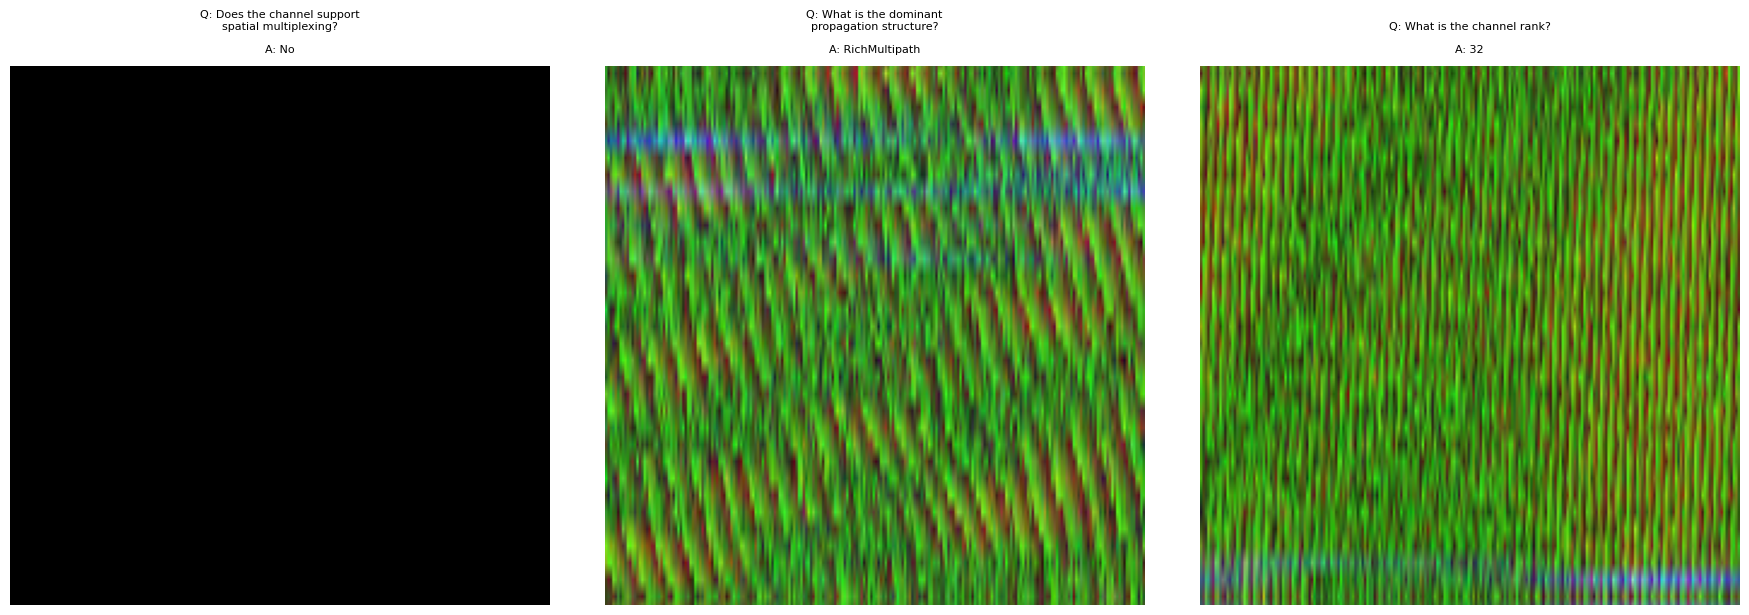

In [25]:
from datasets import load_dataset
import random
import matplotlib.pyplot as plt
import textwrap

#ds = load_dataset("chandrabhuma/csi-vqa-santaclara28Ant8", split="train")
ds = dataset["train"]
random_indices = random.sample(range(len(ds)), 3)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, ax in zip(random_indices, axes):
    sample = ds[idx]
    ax.imshow(sample["image"])

    # Wrap long text
    question = textwrap.fill(sample['question'], width=30)
    answer = textwrap.fill(sample['answer'], width=30)

    ax.set_title(f"Q: {question}\n\nA: {answer}", fontsize=8, pad=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [26]:
##Additional Questions
# import numpy as np

# def extract_channel_features(H):

#     """
#     Extract various communication features from CSI matrix H
#     H shape: (num_antennas, num_subcarriers)
#     """

#     H_mag = np.abs(H)
#     H_phase = np.angle(H)

#     features = {}

#     # ------------------------------------------------
#     # 1. SIGNAL STRENGTH FEATURES
#     # ------------------------------------------------

#     # Average channel gain
#     features["avg_gain"] = np.mean(H_mag)

#     # Maximum gain
#     features["max_gain"] = np.max(H_mag)

#     # Minimum gain
#     features["min_gain"] = np.min(H_mag)

#     # Dynamic range of gains
#     features["gain_range"] = features["max_gain"] - features["min_gain"]

#     # Median channel gain
#     features["median_gain"] = np.median(H_mag)


#     # ------------------------------------------------
#     # 2. FREQUENCY DOMAIN FEATURES
#     # ------------------------------------------------

#     # Deepest fading subcarrier
#     features["deepest_sub"] = int(np.argmin(np.mean(H_mag, axis=0)))

#     # Strongest subcarrier
#     features["strongest_sub"] = int(np.argmax(np.mean(H_mag, axis=0)))

#     # Frequency selectivity
#     features["freq_selectivity"] = np.var(H_mag, axis=0).mean()

#     # Fading variance across subcarriers
#     features["fading_var"] = np.var(H_mag)

#     # Number of deep fades
#     features["deep_fades"] = np.sum(np.mean(H_mag,axis=0) < 0.1*np.max(H_mag))


#     # ------------------------------------------------
#     # 3. SPATIAL (ANTENNA) FEATURES
#     # ------------------------------------------------

#     # Strongest antenna
#     features["strongest_ant"] = int(np.argmax(np.mean(H_mag, axis=1)))

#     # Weakest antenna
#     features["weakest_ant"] = int(np.argmin(np.mean(H_mag, axis=1)))

#     # Variance of antenna gains
#     features["ant_var"] = np.var(np.mean(H_mag, axis=1))

#     # Antenna correlation
#     features["ant_corr"] = np.mean(np.corrcoef(H_mag))

#     # Antenna diversity (spread of gains)
#     features["ant_diversity"] = np.std(np.mean(H_mag, axis=1))


#     # ------------------------------------------------
#     # 4. BEAMFORMING FEATURES
#     # ------------------------------------------------

#     # Beam spectrum using spatial FFT
#     beam_spectrum = np.abs(np.fft.fft(H, axis=0)).mean(axis=1)

#     # Optimal beam index
#     features["best_beam"] = int(np.argmax(beam_spectrum))

#     # Second strongest beam
#     features["second_beam"] = int(np.argsort(beam_spectrum)[-2])

#     # Beam power
#     features["beam_power"] = np.max(beam_spectrum)

#     # Beam dominance ratio
#     features["beam_ratio"] = features["beam_power"] / np.mean(H_mag)


#     # ------------------------------------------------
#     # 5. MIMO FEATURES
#     # ------------------------------------------------

#     # Channel rank
#     features["rank"] = int(np.linalg.matrix_rank(H))

#     # Singular values
#     U,S,V = np.linalg.svd(H)

#     # Condition number
#     features["condition_number"] = S.max()/S.min()

#     # Spatial multiplexing support
#     features["multiplex"] = features["rank"] > 1

#     # Effective channel energy
#     features["eff_power"] = np.sum(S**2)


#     # ------------------------------------------------
#     # 6. PHASE FEATURES
#     # ------------------------------------------------

#     # Phase variance
#     features["phase_var"] = np.var(H_phase)

#     # Mean phase
#     features["phase_mean"] = np.mean(H_phase)

#     # Phase gradient across antennas
#     features["phase_grad"] = np.mean(np.gradient(H_phase, axis=0))


#     # ------------------------------------------------
#     # 7. GLOBAL CHANNEL PROPERTIES
#     # ------------------------------------------------

#     # Channel entropy
#     p = H_mag/np.sum(H_mag)
#     features["entropy"] = -np.sum(p*np.log(p+1e-12))

#     # Channel sparsity
#     features["sparsity"] = np.sum(H_mag < 0.1*np.max(H_mag))

#     # Total channel energy
#     features["energy"] = np.sum(H_mag**2)

#     return features



# def generate_vqa_questions(features):

#     """
#     Convert channel features into VQA question-answer pairs
#     """

#     qa = []

#     qa.append(("Which subcarrier experiences the deepest fading?",
#                f"Subcarrier {features['deepest_sub']}"))

#     qa.append(("Which subcarrier has the strongest channel gain?",
#                f"Subcarrier {features['strongest_sub']}"))

#     qa.append(("Which antenna has the strongest signal?",
#                f"Antenna {features['strongest_ant']}"))

#     qa.append(("Which antenna has the weakest gain?",
#                f"Antenna {features['weakest_ant']}"))

#     qa.append(("What is the average channel gain?",
#                f"{features['avg_gain']:.4f}"))

#     qa.append(("What is the channel rank?",
#                f"{features['rank']}"))

#     qa.append(("Which beam index should be selected?",
#                f"Beam {features['best_beam']}"))

#     qa.append(("What is the second strongest beam?",
#                f"Beam {features['second_beam']}"))

#     qa.append(("Is the channel highly frequency selective?",
#                "Yes" if features["freq_selectivity"]>0.01 else "No"))

#     qa.append(("Does the channel support spatial multiplexing?",
#                "Yes" if features["multiplex"] else "No"))

#     qa.append(("What is the fading variance?",
#                f"{features['fading_var']:.4f}"))

#     qa.append(("What is the beam dominance ratio?",
#                f"{features['beam_ratio']:.4f}"))

#     qa.append(("Is antenna correlation high?",
#                "Yes" if features["ant_corr"]>0.5 else "No"))

#     qa.append(("What is the channel entropy?",
#                f"{features['entropy']:.4f}"))

#     qa.append(("What is the total channel energy?",
#                f"{features['energy']:.4f}"))

#     return qa